# Nesterov's method with a posteriori weights: one-variable and two-variable rules

Updated companion notebook (it supersedes `Section1_adaptive_A.ipynb` and `Section1_adaptive_A_strongly_convex.ipynb` for the $\gamma=L$ variants, and adds the two-variable rule). Same data, preprocessing and constants as `Section1_experiments.ipynb`.

**Common part** ($q=m/L$, $z_0=x_0$, $A_0=0$): from the current $A_k$, Nesterov's weight $a_k=\frac{1+2qA_k+\sqrt{1+4A_k+4qA_k^2}}{2(1-q)}$, $\;y_k=x_k+\tau_k(z_k-x_k)$ with $\tau_k=\frac{a_k(1+qA_k)}{A_k+a_k+2qA_ka_k+qA_k^2}$, $\;x_{k+1}=y_k-\frac1L\nabla f(y_k)$. Guarantee in all cases: $f(x_k)-f_\star\le \frac{L\|x_0-x_\star\|^2}{2A_k}$.

**One-variable rule** (previous notes): the old aggregate keeps weight $A_k$ and $\tilde a_k$ is the largest weight of the new piece keeping the certificate, with $\sigma_k,\delta_k,\rho_k$ the three measured scalars:
$$\tilde a_k=\frac{\beta_k+\sqrt{\beta_k^2+2(1-q\rho_k)(1+qA_k)\delta_kA_k}}{1-q\rho_k},\qquad \beta_k=(1+qA_k)\sigma_k+qA_k\delta_k .$$

**Two-variable rule** (new): the lower model $W_k$ (pieces only) is kept separate from the regularization, and both the weight $\lambda$ of the new piece $q_k$ and the level $A$ are chosen:
$$A_{k+1}=\max\Big\{A:\ \max_{\lambda\in[0,1]}\min_z\Big[(1-\lambda)W_k(z)+\lambda q_k(z)+\tfrac{L}{2A}\|z-x_0\|^2\Big]\ge f(x_{k+1})\Big\}.$$
With $t=A/(1+qA)$, $e_W=W_k(x_0)-f(x_{k+1})$, $G_W=\nabla W_k(x_0)$, $e_Q=q_k(x_0)-f(x_{k+1})$, $G_Q=\nabla f(y_k)+m(x_0-y_k)$:
$$t_{k+1}=\max_{\lambda\in[0,1]}\frac{2L\,[(1-\lambda)e_W+\lambda e_Q]}{\|(1-\lambda)G_W+\lambda G_Q\|^2},\qquad \lambda_\pm=\frac{1}{e_Q-e_W}\Big(-e_W\pm\frac{\|e_WG_Q-e_QG_W\|}{\|G_Q-G_W\|}\Big),$$
the maximum being attained at $\lambda=0$, at $\lambda=1$, or at one of $\lambda_\pm$ in $(0,1)$. Then $A_{k+1}=t_{k+1}/(1-qt_{k+1})$, $W_{k+1}=(1-\lambda_k)W_k+\lambda_kq_k$, $z_{k+1}=x_0-\frac{t_{k+1}}{L}\nabla W_{k+1}(x_0)$.

**Stopping.** All accelerated runs stop when $\|\nabla f(y_k)\|\le10^{-7}\|\nabla f(y_0)\|$ (the last value is then repeated in the plots): beyond that point the measured differences of function values are round-off.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logsumexp, softmax
from sklearn.datasets import load_diabetes

SONAR_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/undocumented/connectionist-bench/sonar/sonar.all-data"
SONAR_FILE = "sonar.csv" if os.path.exists("sonar.csv") else SONAR_URL
_ = np.seterr(divide="ignore", invalid="ignore")

## Problems

Top row of the figure: the three problems of Section 1, methods run with $m=0$. Bottom row: methods run with the true $m>0$ (a ridge term $\frac12\|x\|^2$ is added to the smoothed $\ell_\infty$ problem, which has $m=0$).

In [2]:
def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


def add_intercept(Z):
    return np.hstack([Z, np.ones((Z.shape[0], 1))])


def solve_with_newton(f, grad, hess, x0):
    res = minimize(f, x0, jac=grad, hess=hess, method="trust-exact", options={"gtol": 1e-13, "maxiter": 1000})
    return res.x


diabetes = load_diabetes(scaled=False)
A_diabetes = add_intercept(standardize(diabetes.data))
b_diabetes = standardize(diabetes.target)

sonar = pd.read_csv(SONAR_FILE, header=None)
A_sonar = add_intercept(standardize(sonar.iloc[:, :60].to_numpy(dtype=float)))
y_sonar = np.where(sonar.iloc[:, 60] == "M", 1.0, -1.0)


def least_squares(ridge, n_iter):
    A, b = A_diabetes, b_diabetes
    n, d = A.shape
    f = lambda x: np.sum((A @ x - b) ** 2) / (2 * n) + ridge / 2 * x @ x
    grad = lambda x: A.T @ (A @ x - b) / n + ridge * x
    ev = np.linalg.eigvalsh(A.T @ A / n)
    x_star = np.linalg.solve(A.T @ A / n + ridge * np.eye(d), A.T @ b / n)
    return dict(f=f, grad=grad, L=ev[-1] + ridge, m=ev[0] + ridge, x0=np.zeros(d), x_star=x_star, n_iter=n_iter)


def logistic(ridge, n_iter):
    A, y = A_sonar, y_sonar
    n, d = A.shape
    lam = 1 / n + ridge
    f = lambda x: np.mean(np.logaddexp(0, -y * (A @ x))) + lam / 2 * x @ x
    grad = lambda x: -A.T @ (y * expit(-y * (A @ x))) / n + lam * x
    def hess(x):
        s = expit(A @ x)
        return A.T @ (A * (s * (1 - s))[:, None]) / n + lam * np.eye(d)
    L = np.linalg.eigvalsh(A.T @ A)[-1] / (4 * n) + lam
    return dict(f=f, grad=grad, L=L, m=lam, x0=np.zeros(d), x_star=solve_with_newton(f, grad, hess, np.zeros(d)), n_iter=n_iter)


def smoothed_linf(ridge, n_iter, tau=0.02):
    A, b = A_diabetes, b_diabetes
    n, d = A.shape
    A2, b2 = np.vstack([A, -A]), np.concatenate([b, -b])
    f = lambda x: tau * logsumexp((A2 @ x - b2) / tau) + ridge / 2 * x @ x
    grad = lambda x: A2.T @ softmax((A2 @ x - b2) / tau) + ridge * x
    def hess(x):
        p = softmax((A2 @ x - b2) / tau)
        Ap = A2.T @ p
        return (A2.T @ (A2 * p[:, None]) - np.outer(Ap, Ap)) / tau + ridge * np.eye(d)
    L = np.max(np.sum(A ** 2, axis=1)) / tau + ridge
    return dict(f=f, grad=grad, L=L, m=ridge, x0=np.zeros(d), x_star=solve_with_newton(f, grad, hess, np.zeros(d)), n_iter=n_iter)

runs = {   # name: (problem, value of m given to the methods)
    "Least squares, $m=0$ used": (least_squares(0.0, 1000), 0.0),
    "Logistic regression, $m=0$ used": (logistic(0.0, 1000), 0.0),
    r"Smoothed $\ell_\infty$, $m=0$": (smoothed_linf(0.0, 3000), 0.0),
    "Least squares, $m>0$ used": (least_squares(0.0, 600), None),
    "Logistic regression, $m>0$ used": (logistic(0.0, 600), None),
    r"Smoothed $\ell_\infty$ + ridge 1": (smoothed_linf(1.0, 1200), None),
}
for name, (P, m_used) in runs.items():
    print(f"{name:40s} L = {P['L']:.4g}, m = {P['m']:.3g}, m given to the methods = {P['m'] if m_used is None else m_used:.3g}")

Least squares, $m=0$ used                L = 4.024, m = 0.00856, m given to the methods = 0
Logistic regression, $m=0$ used          L = 3.057, m = 0.00481, m given to the methods = 0
Smoothed $\ell_\infty$, $m=0$            L = 2489, m = 0, m given to the methods = 0
Least squares, $m>0$ used                L = 4.024, m = 0.00856, m given to the methods = 0.00856
Logistic regression, $m>0$ used          L = 3.057, m = 0.00481, m given to the methods = 0.00481
Smoothed $\ell_\infty$ + ridge 1         L = 2490, m = 1, m given to the methods = 1


## Methods

In [3]:
def gd(f, grad, x0, alpha, n_iter):
    x = x0.copy(); values = [f(x)]
    for k in range(n_iter):
        x = x - alpha * grad(x); values.append(f(x))
    return np.array(values)


def nesterov_step(A, q):
    a = (1 + 2 * q * A + np.sqrt(1 + 4 * A + 4 * q * A * A)) / (2 * (1 - q))
    return a, a * (1 + q * A) / (A + a + 2 * q * A * a + q * A * A)


def pad(h, n_iter):
    for key in ("f", "A"):
        h[key] = np.array(h[key] + [h[key][-1]] * (n_iter + 1 - len(h[key])))
    return {key: np.array(v) for key, v in h.items()}


def one_variable(f, grad, x0, L, m, n_iter, adaptive=True, tol=1e-7):
    """adaptive=False: standard Nesterov.  adaptive=True: old aggregate kept at weight A_k, largest a~_k."""
    q = m / L
    x, z, A, fx = x0.copy(), x0.copy(), 0.0, f(x0)
    h = dict(f=[fx], A=[A], ratio=[])
    for k in range(n_iter):
        a, tau = nesterov_step(A, q)
        y = x + tau * (z - x)
        g = grad(y); g2 = g @ g
        if k == 0: g2_0 = g2
        if g2 <= tol ** 2 * g2_0: break
        x_next = y - g / L
        fy, fx_next = f(y), f(x_next)
        sigma = L / g2 * (fy - fx_next + g @ (z - y) + m / 2 * np.sum((z - y) ** 2))
        delta, rho = L / g2 * (fx - fx_next), 2 * L / g2 * (fy - fx_next)
        beta = (1 + q * A) * sigma + q * A * delta
        a_tilde = (beta + np.sqrt(max(beta ** 2 + 2 * (1 - q * rho) * (1 + q * A) * delta * A, 0.0))) / (1 - q * rho)
        step = a_tilde if adaptive else a
        z = ((1 + q * A) * z + step * (q * y - g / L)) / (1 + q * (A + step))
        x, fx, A = x_next, fx_next, A + step
        h["f"].append(fx); h["A"].append(A); h["ratio"].append(a_tilde / a)
    return pad(h, n_iter)


def best_weight(eW, eQ, GW, GQ, L):
    """max over lam in [0,1] of  2L ((1-lam) eW + lam eQ) / ||(1-lam) GW + lam GQ||^2 : candidates 0, 1, lam_+, lam_-"""
    S = lambda lam: 2 * L * ((1 - lam) * eW + lam * eQ) / np.sum(((1 - lam) * GW + lam * GQ) ** 2)
    cands = [0.0, 1.0]
    if eQ != eW:
        r = np.linalg.norm(eW * GQ - eQ * GW) / np.linalg.norm(GQ - GW)
        cands += [lam for lam in ((-eW + r) / (eQ - eW), (-eW - r) / (eQ - eW)) if 0.0 < lam < 1.0]
    vals = [S(lam) for lam in cands]
    i = int(np.argmax(vals))
    return vals[i], cands[i], S


def two_variable(f, grad, x0, L, m, n_iter, tol=1e-7):
    q = m / L
    x, t, W, GW = x0.copy(), 0.0, None, np.zeros_like(x0)
    h = dict(f=[f(x0)], A=[0.0], ratio=[], lam=[], grid_excess=[], tight=[], lam_oqa=[], oqa_gap=[], centre2=[])
    grid = np.linspace(0, 1, 401)
    for k in range(n_iter):
        A = t / (1 - q * t)
        z = x0 - t / L * GW
        a, tau = nesterov_step(A, q)
        y = x + tau * (z - x)
        g = grad(y); g2 = g @ g
        if k == 0: g2_0 = g2
        if g2 <= tol ** 2 * g2_0: break
        x_next = y - g / L
        fy, fx_next = f(y), f(x_next)
        Q = fy + g @ (x0 - y) + m / 2 * np.sum((x0 - y) ** 2)          # value of the new piece at x0
        GQ = g + m * (x0 - y)                                          # gradient of the new piece at x0
        if W is None:
            t_new, lam = 2 * L * (Q - fx_next) / (GQ @ GQ), 1.0
        else:
            eW, eQ = W - fx_next, Q - fx_next
            t_new, lam, S = best_weight(eW, eQ, GW, GQ, L)
            # checks: no weight on a fine grid does better; the certificate is tight at (t_new, lam)
            h["grid_excess"].append(max(S(l) for l in grid) / t_new - 1)
            G_lam = (1 - lam) * GW + lam * GQ
            h["tight"].append(((1 - lam) * eW + lam * eQ - t_new / (2 * L) * (G_lam @ G_lam)) / abs((1 - lam) * eW + lam * eQ))
            h["lam"].append(lam)
            if m > 0:                                                  # optimal quadratic averaging of the same two pieces
                dG = GQ - GW
                lam_o = min(max((m * (Q - W) - GW @ dG) / (dG @ dG), 0.0), 1.0)
                G_o = GW + lam_o * dG
                h["lam_oqa"].append(lam_o)
                h["oqa_gap"].append(fx_next - ((1 - lam_o) * W + lam_o * Q - (G_o @ G_o) / (2 * m)))
                h["centre2"].append((G_o @ G_o) / m ** 2)              # ||c_k - x0||^2, c_k minimiser of max{W_k, q_k}
        A_new = t_new / (1 - q * t_new)
        W, GW = (Q, GQ) if W is None else ((1 - lam) * W + lam * Q, (1 - lam) * GW + lam * GQ)
        h["ratio"].append((A_new - A) / a)
        x, t = x_next, t_new
        h["f"].append(fx_next); h["A"].append(A_new)
    return pad(h, n_iter)

## Runs and checks

In [4]:
results = {}
for name, (P, m_used) in runs.items():
    m = P["m"] if m_used is None else m_used
    args = (P["f"], P["grad"], P["x0"], P["L"], m, P["n_iter"])
    results[name] = dict(m=m, f_star=P["f"](P["x_star"]), R2=np.sum((P["x0"] - P["x_star"]) ** 2),
                         gd=gd(P["f"], P["grad"], P["x0"], 1 / P["L"], P["n_iter"]),
                         std=one_variable(*args, adaptive=False), one=one_variable(*args), two=two_variable(*args))


def first_below(gap, tol=1e-10):
    return int(np.argmax(gap < tol)) if (gap < tol).any() else "-"


def checks(P, R):
    L, fs, n = P["L"], R["f_star"], P["n_iter"]
    one, two, std = R["one"], R["two"], R["std"]
    lam = two["lam"]; K = len(lam); third = slice(2 * K // 3, K)
    row = {
        "m given to the methods": f"{R['m']:.3g}",
        "steps before the stopping test (two-variable)": f"{len(two['ratio'])}",
        "one-variable: steps with a~_k < a_k": f"{int(np.sum(one['ratio'] < 1 - 1e-9))}",
        "two-variable: steps with A_k+1 - A_k < a_k": f"{int(np.sum(two['ratio'] < 1 - 1e-9))}",
        "median (A_k+1 - A_k)/a_k: one / two": f"{np.median(one['ratio']):.2f} / {np.median(two['ratio']):.2f}",
        "closed form vs best of 401 weights: max excess": f"{np.max(two['grid_excess']):.1e}",
        "certificate tight at (t, lam): max |residual|": f"{np.max(np.abs(two['tight'])):.1e}",
        "share of steps: interior / lam=0 / lam=1": f"{np.mean((lam > 0) & (lam < 1)):.2f} / {np.mean(lam == 0):.2f} / {np.mean(lam == 1):.2f}",
        "max A_k (f(x_k)-f*) / (L/2 |x0-x*|^2): one / two": f"{np.max(one['A'] * (one['f'] - fs)) / (L / 2 * R['R2']):.3f} / {np.max(two['A'] * (two['f'] - fs)) / (L / 2 * R['R2']):.3f}",
        "n (iterations)": f"{n}",
        "gap at k = n/10: GD / standard / one / two": " / ".join(f"{v[n // 10] - fs:.1e}" for v in (R["gd"], std["f"], one["f"], two["f"])),
        "gap at k = n: GD / standard / one / two": " / ".join(f"{v[-1] - fs:.1e}" for v in (R["gd"], std["f"], one["f"], two["f"])),
        "first k with gap < 1e-10: standard / one / two": " / ".join(str(first_below(v["f"] - fs)) for v in (std, one, two)),
    }
    if R["m"] > 0:
        A_next = two["A"][2:K + 2]
        row["last third: median |lam_k - OQA weight|"] = f"{np.median(np.abs(lam - two['lam_oqa'])[third]):.1e}"
        row["last third: median [L|c_k-x0|^2/(2A_k+1)] / OQA gap"] = f"{np.median((L * two['centre2'] / (2 * A_next) / two['oqa_gap'])[third]):.4f}"
    return row


short = lambda s: s.replace(r"$\ell_\infty$", "l_inf").replace("$", "").replace("Smoothed ", "").replace(" regression", "")
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
table = pd.DataFrame({short(name): checks(P, results[name]) for name, (P, _) in runs.items()}).fillna("")
table.iloc[:, :3]

,"Least squares, m=0 used","Logistic, m=0 used","l_inf, m=0"
m given to the methods,0,0,0
steps before the stopping test (two-variable),1000,1000,3000
one-variable: steps with a~_k < a_k,0,0,0
two-variable: steps with A_k+1 - A_k < a_k,0,0,0
median (A_k+1 - A_k)/a_k: one / two,2.00 / 1.42,2.91 / 5.78,5.37 / 2.32
closed form vs best of 401 weights: max excess,0.0e+00,0.0e+00,0.0e+00
"certificate tight at (t, lam): max |residual|",4.4e-16,6.7e-16,5.0e-16
share of steps: interior / lam=0 / lam=1,0.98 / 0.02 / 0.00,0.99 / 0.00 / 0.01,0.99 / 0.00 / 0.01
max A_k (f(x_k)-f*) / (L/2 |x0-x*|^2): one / two,0.218 / 0.358,0.186 / 0.400,0.469 / 0.578
n (iterations),1000,1000,3000


In [5]:
table.iloc[:, 3:]

,"Least squares, m>0 used","Logistic, m>0 used",l_inf + ridge 1
m given to the methods,0.00856,0.00481,1
steps before the stopping test (two-variable),246,259,531
one-variable: steps with a~_k < a_k,0,0,0
two-variable: steps with A_k+1 - A_k < a_k,0,0,0
median (A_k+1 - A_k)/a_k: one / two,2.03 / 2.04,2.26 / 2.40,2.16 / 2.27
closed form vs best of 401 weights: max excess,4.4e-16,4.4e-16,4.4e-16
"certificate tight at (t, lam): max |residual|",4.2e-16,4.8e-16,4.2e-16
share of steps: interior / lam=0 / lam=1,0.78 / 0.21 / 0.01,0.92 / 0.00 / 0.08,0.49 / 0.00 / 0.51
max A_k (f(x_k)-f*) / (L/2 |x0-x*|^2): one / two,0.632 / 1.000,0.221 / 0.902,0.660 / 0.930
n (iterations),600,600,1200


**Reading the tables.**

- Both rules give increments at least equal to Nesterov's $a_k$ at every step, and $A_k(f(x_k)-f_\star)\le\frac L2\|x_0-x_\star\|^2$.
- The closed form of the two-variable rule is optimal (no weight on a grid of 401 values gives a larger $t$) and the certificate is tight at the selected pair; the three cases (interior weight, $\lambda=0$, $\lambda=1$) all occur.
- For $m>0$, the selected weight approaches the optimal-quadratic-averaging weight of the same two pieces, and $L\|c_k-x_0\|^2/(2A_{k+1})$ approaches the duality gap $f(x_{k+1})-\min_z\max\{W_k,q_k\}$.
- In function values the two-variable rule is slightly ahead for $m>0$ and behind the one-variable rule for $m=0$.

## Figure

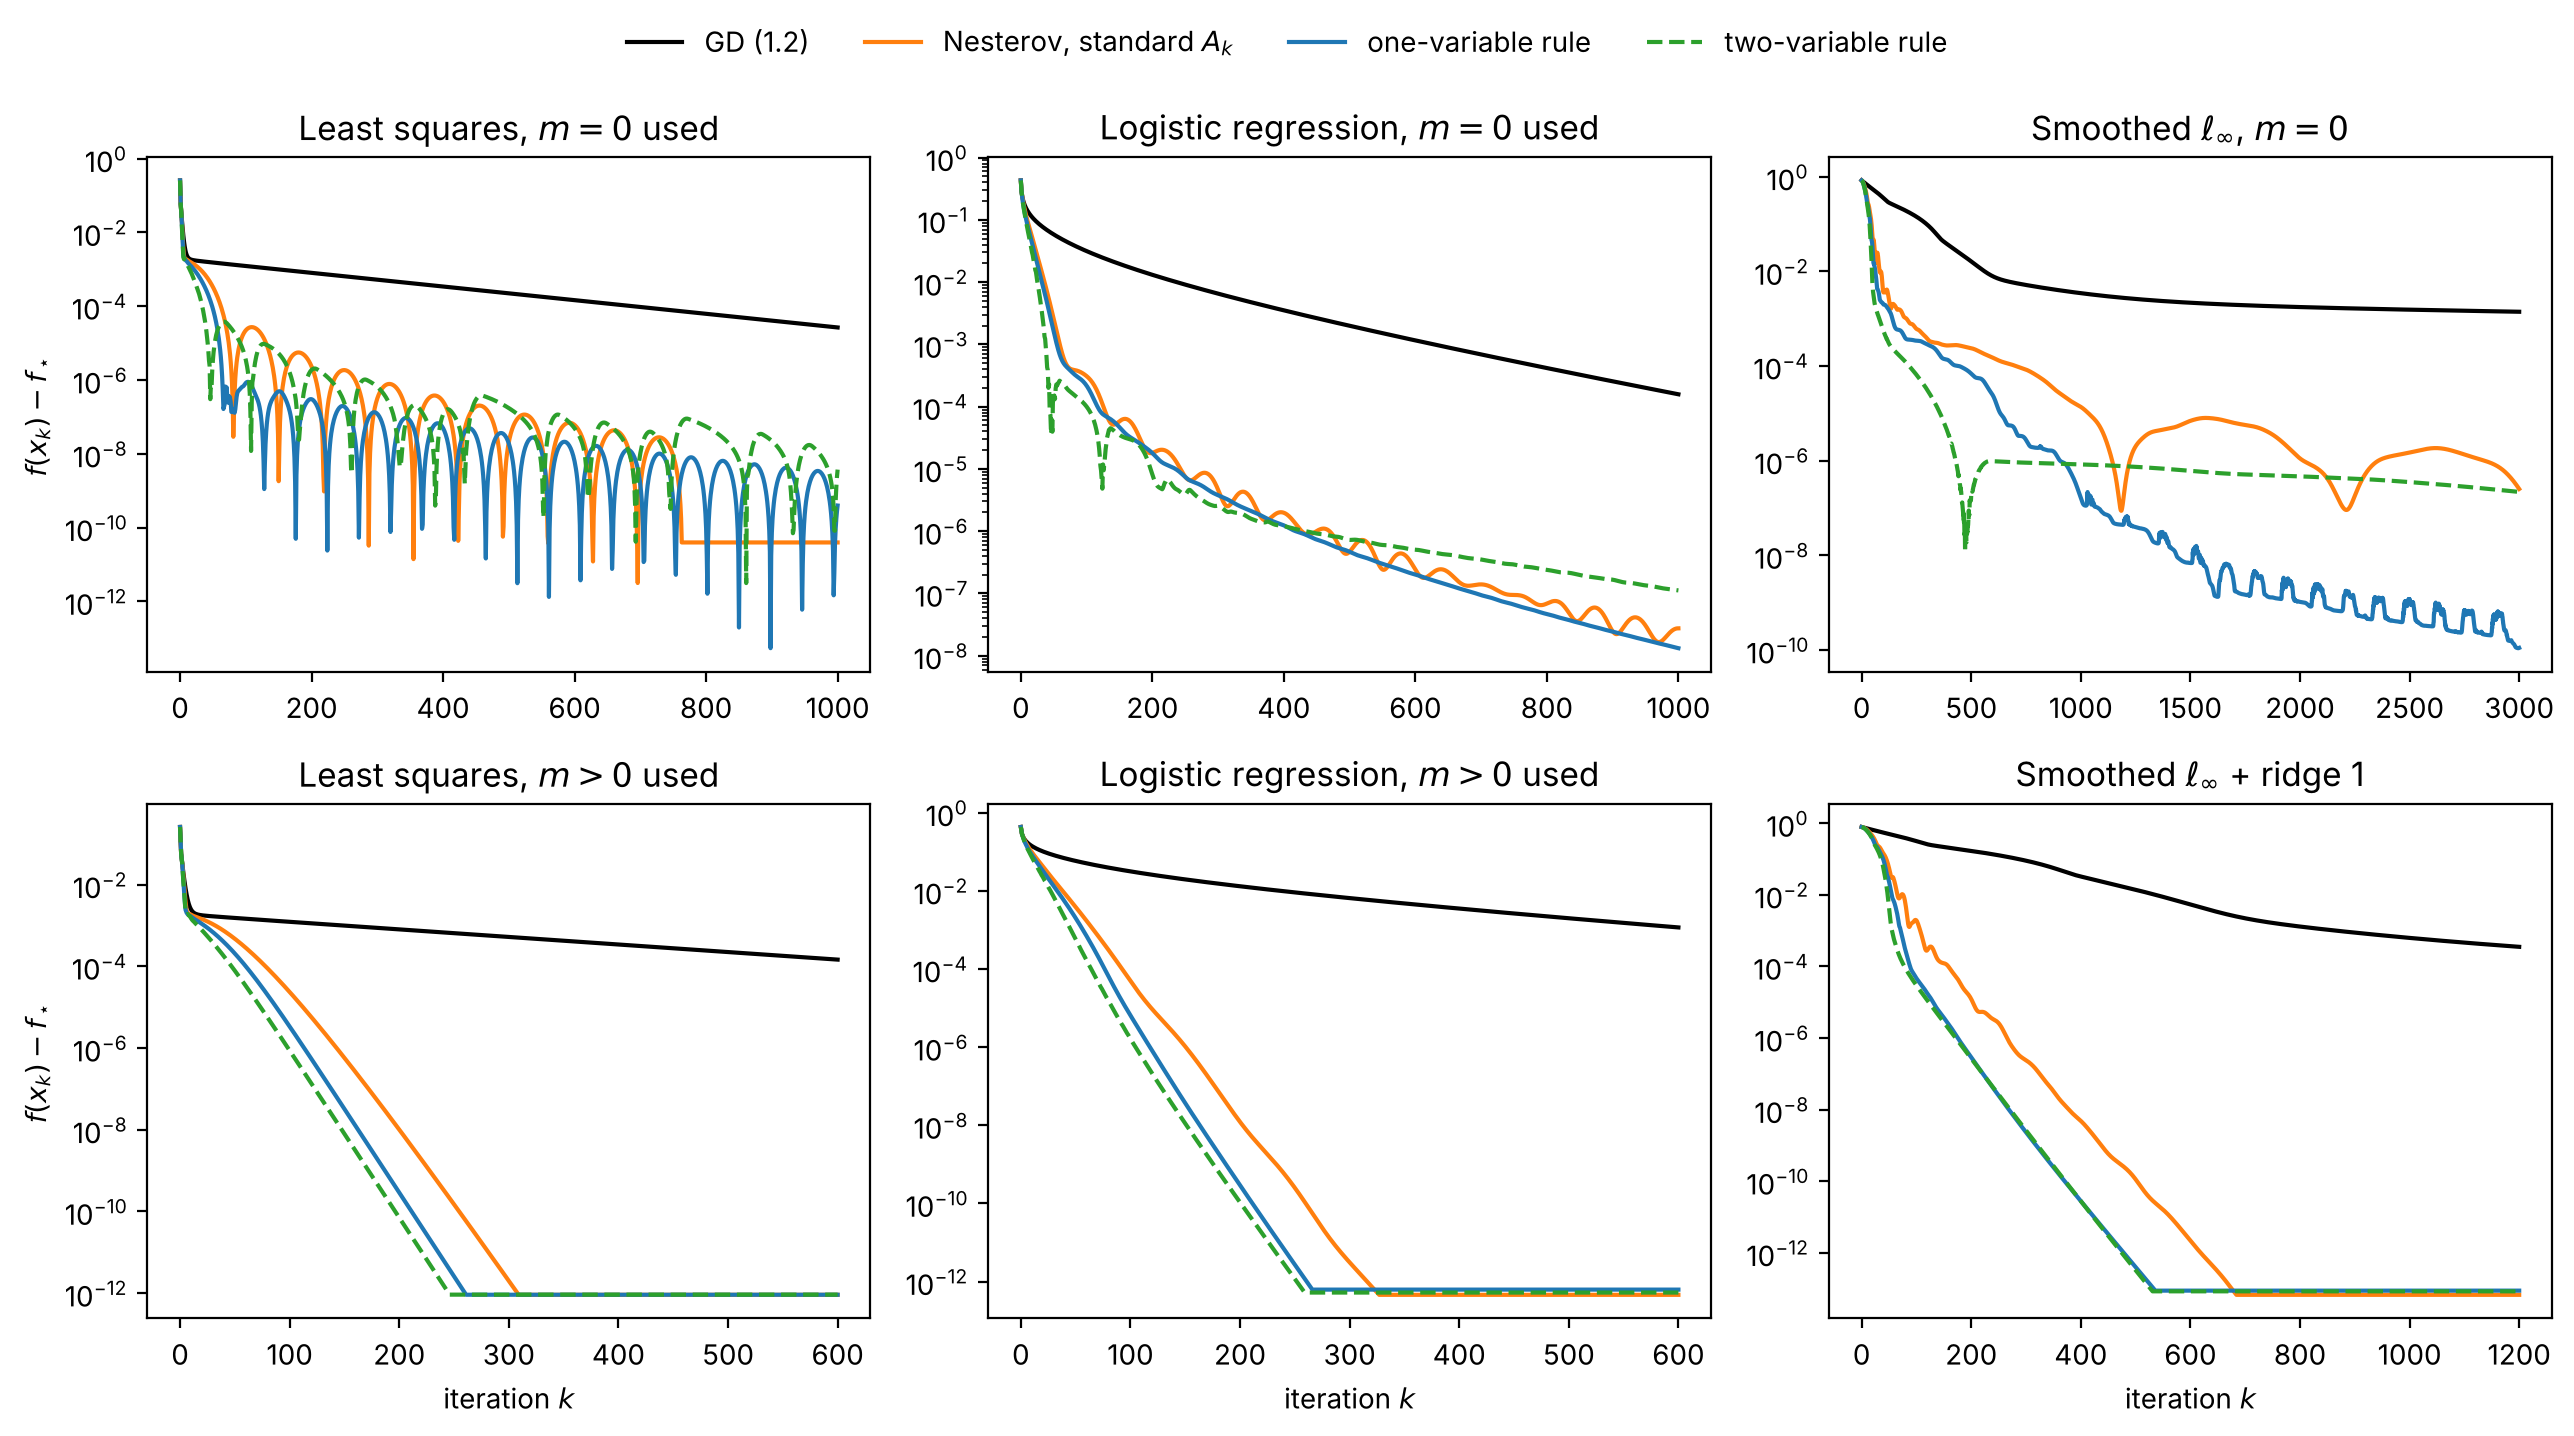

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, (name, (P, _)) in zip(axes.ravel(), runs.items()):
    R = results[name]; fs = R["f_star"]
    ax.semilogy(np.maximum(R["gd"] - fs, 1e-16), color="black", label="GD (1.2)")
    ax.semilogy(np.maximum(R["std"]["f"] - fs, 1e-16), color="tab:orange", label="Nesterov, standard $A_k$")
    ax.semilogy(np.maximum(R["one"]["f"] - fs, 1e-16), color="tab:blue", label="one-variable rule")
    ax.semilogy(np.maximum(R["two"]["f"] - fs, 1e-16), color="tab:green", ls="--", label="two-variable rule")
    ax.set_title(name)
for ax in axes[1]: ax.set_xlabel("iteration $k$")
for ax in axes[:, 0]: ax.set_ylabel(r"$f(x_k) - f_\star$")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("adaptive_A_one_vs_two_variable.png", dpi=130)
plt.show()